<a href="https://colab.research.google.com/github/nguyenanhthu000000/Machine-learning/blob/main/05.%20DecisionTree_RandomForest/NguyenAnhThu_2474802010381_lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
# -*- coding: utf-8 -*-
"""Bước 1: tự tính chỉ số Gini và tự chọn câu hỏi tốt nhất.
"""

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)

g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong   Gini sau chia   Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f} {g:13.4f} {g_goc - g:9.4f}")
print()

viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong   Gini sau chia   Gini giam
    7.0        0.4000    0.0800
    8.5        0.4750    0.0050
   10.0        0.4190    0.0610
   12.0        0.3167    0.1633
   14.0        0.4000    0.0800
   16.5        0.4500    0.0300
   19.0        0.3429    0.1371
   22.5        0.4000    0.0800
   27.5        0.4444    0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



In [36]:
"""Bước 2: học một cây nhỏ năm lá trên dữ liệu khách vay rồi đọc nó."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc       : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

In [37]:
"""Bước 3: để cây mọc tự do, rồi chọn độ sâu bằng kiểm định chéo."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

print("Do sau    tap hoc    kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d}      {hoc:.4f}      {diem[d]:.4f}")

d_tot = max(diem, key=diem.get)
print()

tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau    tap hoc    kiem dinh cheo
  1      0.7467      0.7244
  2      0.7711      0.7378
  3      0.8000      0.7511
  4      0.8644      0.8089
  5      0.8978      0.8333
  6      0.9133      0.8156
  7      0.9400      0.8067
  8      0.9600      0.7733
  9      0.9800      0.7800
 10      0.9911      0.7822
 11      0.9933      0.7756
 12      0.9978      0.7778
 13      1.0000      0.7733
 14      1.0000      0.7733
 15      1.0000      0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


In [38]:
# -*- coding: utf-8 -*-
"""Bước 4: kiểm chứng cây không cần chuẩn hoá dữ liệu."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)

goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc         : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa        : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong : {accuracy_score(y_te, du_nghin):.4f}")
print()

print("So khach bi doan khac cay goc")
print(f" da chuan hoa        : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong : {(du_nghin != du_goc).sum()}")
print()

print("Nguong cua cau hoi goc")
print(f" du lieu goc         : {goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong : {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
 du lieu goc         : 0.8533
 da chuan hoa        : 0.8533
 thu nhap nghin dong : 0.8533

So khach bi doan khac cay goc
 da chuan hoa        : 0
 thu nhap nghin dong : 0

Nguong cua cau hoi goc
 du lieu goc         : 15.05
 thu nhap nghin dong : 15050.00


In [39]:
# -*- coding: utf-8 -*-
"""Bước 5: trồng rừng ngẫu nhiên và so với một cây."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"  tap hoc      : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"  tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay | Accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f" {m:4d}  | {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}

print(f"{'Mo hinh':14s} | tap hoc | tap kiem tra")
print("-" * 37)
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f"{ten:14s} |  {a:.4f} |  {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
  tap hoc      : 1.0000
  tap kiem tra : 0.9000

So cay | Accuracy tap kiem tra
    1  | 0.7933
   10  | 0.8467
   50  | 0.8733
  200  | 0.9000
  400  | 0.9000

Mo hinh        | tap hoc | tap kiem tra
-------------------------------------
Cay moc tu do  |  1.0000 |  0.7667
Cay sau 5      |  0.8978 |  0.8533
Rung 200 cay   |  1.0000 |  0.9000


In [40]:
# -*- coding: utf-8 -*-
"""Bước 7: cây quyết định cho bài toán hồi quy, trên dữ liệu giá nhà."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"  Cay sau 3  : {mae_cay:.4f}")
print(f"  Duong thang: {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(f"{'Dien tich':>10s} | {'Cay':>8s} | {'Duong thang':>11s}")
print("-" * 35)

for dt, a, b in zip(
    can_moi["dien_tich"], cay.predict(can_moi), duong.predict(can_moi)
):
    print(f"{dt:8.0f} m2 | {a:8.2f} | {b:11.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
  Cay sau 3  : 0.5039
  Duong thang: 0.2578

Du doan cho bon can moi (ty dong)
 Dien tich |      Cay | Duong thang
-----------------------------------
      60 m2 |     4.92 |        5.12
     100 m2 |     8.32 |        8.24
     150 m2 |     9.40 |       12.13
     250 m2 |     9.40 |       19.9

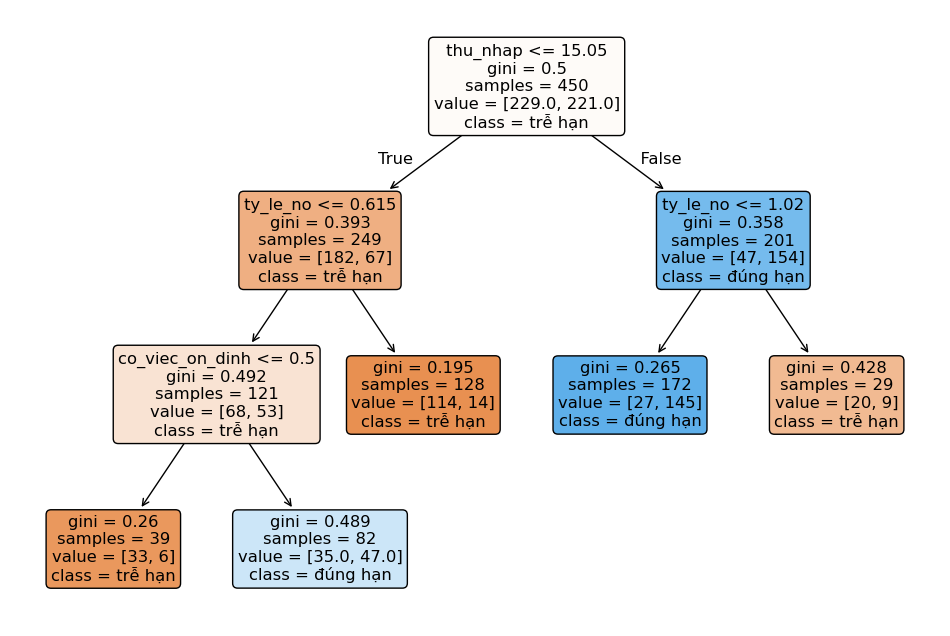

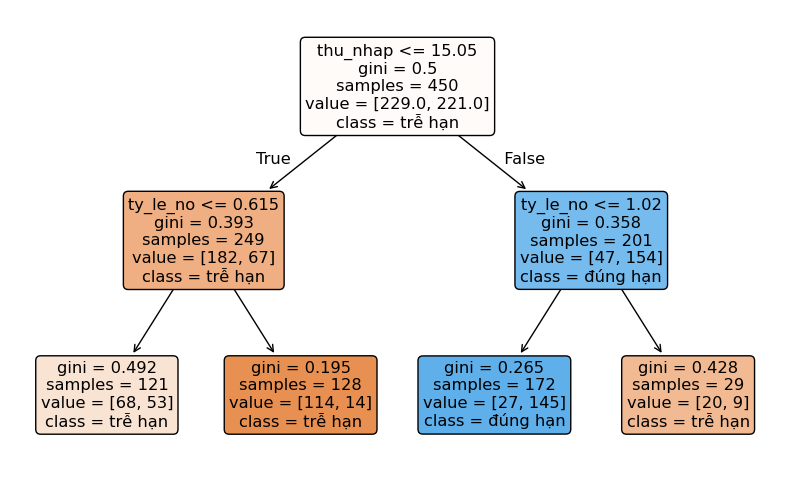

Nhận xét: 
- Hai lá bên trái của cây sâu 2 dù có thể đưa ra cùng một kết luận dự đoán (ví dụ: cùng dự đoán là 'trễ hạn'), nhưng cây vẫn phân tách nút đó ra làm hai nhánh con vì tỷ lệ phân phối mẫu (số lượng mẫu lớp 0 và lớp 1) hoặc chỉ số Gini ở mỗi nhánh là khác nhau, giúp tối ưu hóa độ thuần khiết của nút tốt hơn trước khi dừng lại


In [41]:
# Bài 1
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay_5_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_5_la.fit(X_tr, y_tr)

plt.figure(figsize=(12, 8))
plot_tree(
    cay_5_la,
    feature_names=list(X.columns),
    class_names=["trễ hạn", "đúng hạn"],
    filled=True,
    rounded=True,
)
plt.savefig("cay_nam_la.png", dpi=300, bbox_inches="tight")
plt.show()

cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_sau_2.fit(X_tr, y_tr)

plt.figure(figsize=(10, 6))
plot_tree(
    cay_sau_2,
    feature_names=list(X.columns),
    class_names=["trễ hạn", "đúng hạn"],
    filled=True,
    rounded=True,
)
plt.show()

print("Nhận xét: ")
print(
    "- Hai lá bên trái của cây sâu 2 dù có thể đưa ra cùng một kết luận dự"
    " đoán (ví dụ: cùng dự đoán là 'trễ hạn'), nhưng cây vẫn phân tách nút"
    " đó ra làm hai nhánh con vì tỷ lệ phân phối mẫu (số lượng mẫu lớp 0 và"
    " lớp 1) hoặc chỉ số Gini ở mỗi nhánh là khác nhau, giúp tối ưu hóa độ"
    " thuần khiết của nút tốt hơn trước khi dừng lại"
)

In [42]:
# Bài 2
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def gini(nhan):
  if len(nhan) == 0:
    return 0.0
  p1 = nhan.mean()
  return 1.0 - p1**2 - (1.0 - p1) ** 2


def gini_sau_chia(y, di_trai):
  trai = y[di_trai]
  phai = y[~di_trai]
  n = len(y)
  if len(trai) == 0 or len(phai) == 0:
    return float("inf")
  return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


def tim_cau_hoi(X, y):
  g_goc = gini(y)
  tot_cot = None
  tot_nguong = None
  min_g_chia = float("inf")

  for col in X.columns:
    col_vals = X[col].to_numpy()
    muc = np.sort(np.unique(col_vals))
    for a, b in zip(muc[:-1], muc[1:]):
      nguong = (a + b) / 2
      g_chia = gini_sau_chia(y, col_vals <= nguong)
      if g_chia < min_g_chia:
        min_g_chia = g_chia
        tot_cot = col
        tot_nguong = nguong

  return tot_cot, tot_nguong, g_goc - min_g_chia


cot, nguong, giam = tim_cau_hoi(X_tr, y_tr)
print(f"Cột tốt nhất    : {cot}")
print(f"Ngưỡng tốt nhất : {nguong}")
print(f"Mức Gini giảm   : {giam:.4f}\n")

print("giải thích")
print(
    "- Thuật toán hoạt động theo cách 'tham lam' (greedy): duyệt qua toàn bộ"
    " các cột và mọi giá trị ngưỡng nằm giữa các mức giá trị liền nhau, sau đó"
    " tính toán chỉ số Gini sau khi chia (Gini trung bình có trọng số) cho từng"
    " trường hợp"
)
print(
    "- Ngưỡng và cột nào làm cho Gini sau khi chia đạt giá trị nhỏ nhất (tức"
    " là mức Gini giảm nhiều nhất) sẽ được chọn làm câu hỏi tối ưu tại nút gốc"
)
print(
    "- Kết quả tìm được là cột 'thu_nhap' với ngưỡng '15.05', khớp hoàn toàn"
    " với câu hỏi gốc của cây quyết định"
)

Cột tốt nhất    : thu_nhap
Ngưỡng tốt nhất : 15.05
Mức Gini giảm   : 0.1221

giải thích
- Thuật toán hoạt động theo cách 'tham lam' (greedy): duyệt qua toàn bộ các cột và mọi giá trị ngưỡng nằm giữa các mức giá trị liền nhau, sau đó tính toán chỉ số Gini sau khi chia (Gini trung bình có trọng số) cho từng trường hợp
- Ngưỡng và cột nào làm cho Gini sau khi chia đạt giá trị nhỏ nhất (tức là mức Gini giảm nhiều nhất) sẽ được chọn làm câu hỏi tối ưu tại nút gốc
- Kết quả tìm được là cột 'thu_nhap' với ngưỡng '15.05', khớp hoàn toàn với câu hỏi gốc của cây quyết định


In [43]:
# Bài 3
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

diem_entropy = {}
for d in range(1, 16):
  mh = DecisionTreeClassifier(
      max_depth=d, criterion="entropy", random_state=0
  )
  diem_entropy[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()

d_tot_ent = max(diem_entropy, key=diem_entropy.get)
print(f"Độ sâu tốt nhất (Entropy)        : {d_tot_ent}")
print(f"Điểm CV tốt nhất                 : {diem_entropy[d_tot_ent]:.4f}")

tot_ent = DecisionTreeClassifier(
    max_depth=d_tot_ent, criterion="entropy", random_state=0
)
tot_ent.fit(X_tr, y_tr)
acc_ent = accuracy_score(y_te, tot_ent.predict(X_te))
print(f"Accuracy trên tập kiểm tra (Ent) : {acc_ent:.4f}\n")

print("Nhận xét")
print(
    "- Việc thay đổi thước đo độ lẫn lộn từ Gini sang Entropy không làm kết"
    " quả thay đổi đáng kể (độ sâu tối ưu và độ chính xác trên tập kiểm tra"
    " rất tương đương), vì cả hai thước đo đều phản ánh mức độ thuần khiết"
    " của nút theo cùng một xu hướng."
)

Độ sâu tốt nhất (Entropy)        : 5
Điểm CV tốt nhất                 : 0.8222
Accuracy trên tập kiểm tra (Ent) : 0.8467

Nhận xét
- Việc thay đổi thước đo độ lẫn lộn từ Gini sang Entropy không làm kết quả thay đổi đáng kể (độ sâu tối ưu và độ chính xác trên tập kiểm tra rất tương đương), vì cả hai thước đo đều phản ánh mức độ thuần khiết của nút theo cùng một xu hướng.


In [44]:
# Bài 4
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

giatri_msl = [1, 2, 5, 10, 20, 40]
diem_msl = {}

for msl in giatri_msl:
  mh = DecisionTreeClassifier(min_samples_leaf=msl, random_state=0)
  diem_msl[msl] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
  print(f"min_samples_leaf = {msl:2d} | CV score = {diem_msl[msl]:.4f}")

msl_tot = max(diem_msl, key=diem_msl.get)
print(f"\nGiá trị min_samples_leaf tốt nhất : {msl_tot}")

tot_msl = DecisionTreeClassifier(min_samples_leaf=msl_tot, random_state=0)
tot_msl.fit(X_tr, y_tr)
acc_msl = accuracy_score(y_te, tot_msl.predict(X_te))
print(f"Accuracy trên tập kiểm tra        : {acc_msl:.4f}\n")

print("Nhận xét")
print(
    "- Cả hai phương pháp cắt tỉa (giới hạn độ sâu max_depth và giới hạn số"
    " lượng mẫu tối thiểu ở lá min_samples_leaf) đều giúp chống hiện tượng"
    " quá khớp hiệu quả."
)
print(
    "- Việc chọn min_samples_leaf phù hợp giúp đảm bảo mỗi lá có đủ lượng mẫu"
    " đại diện, tránh việc cây tự do chia nhỏ các ô chữ nhật quá mức để ôm"
    " lấy các mẫu nhiễu."
)

min_samples_leaf =  1 | CV score = 0.7733
min_samples_leaf =  2 | CV score = 0.7822
min_samples_leaf =  5 | CV score = 0.8067
min_samples_leaf = 10 | CV score = 0.8089
min_samples_leaf = 20 | CV score = 0.8089
min_samples_leaf = 40 | CV score = 0.7133

Giá trị min_samples_leaf tốt nhất : 10
Accuracy trên tập kiểm tra        : 0.8467

Nhận xét
- Cả hai phương pháp cắt tỉa (giới hạn độ sâu max_depth và giới hạn số lượng mẫu tối thiểu ở lá min_samples_leaf) đều giúp chống hiện tượng quá khớp hiệu quả.
- Việc chọn min_samples_leaf phù hợp giúp đảm bảo mỗi lá có đủ lượng mẫu đại diện, tránh việc cây tự do chia nhỏ các ô chữ nhật quá mức để ôm lấy các mẫu nhiễu.


In [45]:
# Bài 5
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))

X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))

rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

result = permutation_importance(
    rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0, n_jobs=-1
)

qt_perm = pd.Series(result.importances_mean, index=X_tr_nn.columns)
print("Độ quan trọng bằng permutation_importance:")
print(qt_perm.sort_values(ascending=False).round(4).to_string())
print()

print("giải thích")
print(
    "- Theo feature_importances_ mặc định, cột ngẫu nhiên thường xếp hạng khá"
    " cao (thậm chí xếp trên cả các cột thật như việc làm ổn định hay số"
    " người phụ thuộc) vì cột có nhiều giá trị khác nhau (như số thực ngẫu"
    " nhiên) luôn có lợi thế được cây chọn để tách vài mẫu trong quá trình huấn luyện"
)
print(
    "- Ngược lại, khi đo bằng permutation_importance trên tập kiểm tra, cột"
    " ngẫu nhiên sẽ rớt xuống vị trí thấp nhất (gần bằng 0 hoặc âm) vì khi xáo"
    " trộn giá trị của nó, độ chính xác (accuracy) của mô hình hoàn toàn không"
    " bị ảnh hưởng, chứng minh rằng cột đó thực chất hoàn toàn vô dụng"
)

Độ quan trọng bằng permutation_importance:
thu_nhap              0.3073
ty_le_no              0.1993
co_viec_on_dinh       0.1117
so_nguoi_phu_thuoc    0.0497
so_ngau_nhien         0.0017

giải thích
- Theo feature_importances_ mặc định, cột ngẫu nhiên thường xếp hạng khá cao (thậm chí xếp trên cả các cột thật như việc làm ổn định hay số người phụ thuộc) vì cột có nhiều giá trị khác nhau (như số thực ngẫu nhiên) luôn có lợi thế được cây chọn để tách vài mẫu trong quá trình huấn luyện
- Ngược lại, khi đo bằng permutation_importance trên tập kiểm tra, cột ngẫu nhiên sẽ rớt xuống vị trí thấp nhất (gần bằng 0 hoặc âm) vì khi xáo trộn giá trị của nó, độ chính xác (accuracy) của mô hình hoàn toàn không bị ảnh hưởng, chứng minh rằng cột đó thực chất hoàn toàn vô dụng


In [46]:
# Bài 6
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

rung_hq = RandomForestRegressor(n_estimators=200, random_state=0)
rung_hq.fit(X_tr, y_tr)

cay_hq = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

mae_rung = mean_absolute_error(y_te, rung_hq.predict(X_te))
mae_cay = mean_absolute_error(y_te, cay_hq.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))

print(f"MAE Rừng ngẫu nhiên (200 cây) : {mae_rung:.4f} tỷ")
print(f"MAE Cây sâu 3                : {mae_cay:.4f} tỷ")
print(f"MAE Đường thẳng              : {mae_duong:.4f} tỷ")

can_250 = pd.DataFrame({"dien_tich": [250.0]})
print(
    "Dự đoán giá căn 250m2 bằng Rừng : "
    f"{rung_hq.predict(can_250)[0]:.2f} tỷ\n"
)

print("giải thích")
print(
    "- Rừng ngẫu nhiên (cũng như cây quyết định) KHÔNG thể ngoại suy được"
)
print(
    "- Khi dự đoán cho căn nhà có diện tích lớn (ví dụ 250 m2, vượt quá khoảng"
    " diện tích tối đa có trong tập huấn luyện), các cây trong rừng sẽ đưa mẫu"
    " này rơi vào các lá tận cùng chứa nhóm căn nhà rộng nhất từng thấy trong"
    " tập học và lấy giá trị trung bình giá của nhóm đó"
)
print(
    "- Do đó, mô hình không thể kéo dài xu hướng tăng tuyến tính ra ngoài"
    " khoảng dữ liệu mẫu đã học mà bị 'kẹt' ở mức giá trung bình của lá cuối cùng"
)


MAE Rừng ngẫu nhiên (200 cây) : 0.4559 tỷ
MAE Cây sâu 3                : 0.5039 tỷ
MAE Đường thẳng              : 0.2578 tỷ
Dự đoán giá căn 250m2 bằng Rừng : 9.20 tỷ

giải thích
- Rừng ngẫu nhiên (cũng như cây quyết định) KHÔNG thể ngoại suy được
- Khi dự đoán cho căn nhà có diện tích lớn (ví dụ 250 m2, vượt quá khoảng diện tích tối đa có trong tập huấn luyện), các cây trong rừng sẽ đưa mẫu này rơi vào các lá tận cùng chứa nhóm căn nhà rộng nhất từng thấy trong tập học và lấy giá trị trung bình giá của nhóm đó
- Do đó, mô hình không thể kéo dài xu hướng tăng tuyến tính ra ngoài khoảng dữ liệu mẫu đã học mà bị 'kẹt' ở mức giá trung bình của lá cuối cùng
